# Predicción del rendimiento académico: optimización de hiperparámetros y comparación de optimizadores

**Optimización e Inteligencia Artificial, UNAL**

**Integrantes:** Juan José Munera Pulgarín, María Cristina Narváez, Sebastián Rodríguez Suarez, Santiago Vanegas Vasquez, Nicolás Ruiz Blandón

**Problema:** regresión del `Exam_Score` (0–100) con el dataset *Student Performance Factors* (Kaggle).

**Optimización involucrada:**
- **Enfoque A, hiperparámetros:** minimizar el MSE de validación cruzada respecto a los hiperparámetros $\theta$, $\min_\theta \; \text{MSE}_{CV}(\theta)$, comparando Grid Search, Random Search, optimización bayesiana, algoritmo genético y PSO.
- **Enfoque B, entrenamiento:** minimizar el MSE respecto a los pesos $w$ de una red neuronal, comparando SGD, SGD con momentum, RMSprop y Adam.

## 0. Configuración

Instalamos e importamos las librerías. Además de sklearn, usamos las mismas librerías de optimización vistas en clase: `scikit-optimize` para la búsqueda bayesiana, `pygad` para el algoritmo genético y `pymetaheuristic` para PSO.

In [1]:
#Instalamos las librerías que se usaron en clase (en Colab hace falta; en el venv local ya están)
# - scikit-optimize: optimización bayesiana (BayesSearchCV)
# - pygad: algoritmo genético
# - pymetaheuristic: PSO
# - kagglehub: descarga del dataset desde Kaggle
%pip install -q scikit-optimize pygad pymetaheuristic kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
#Importacion de librerias
import os
# Silencia los avisos también en los procesos paralelos de joblib (heredan esta variable)
os.environ["PYTHONWARNINGS"] = "ignore"
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Herramientas de sklearn: partición de datos, validación cruzada y búsquedas de hiperparámetros
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
#Preprocesamiento: imputación, codificación de categóricas y escalado dentro de un pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
#Los tres modelos de regresión que vamos a comparar
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
#Métricas de evaluación para regresión
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
#Distribuciones para el muestreo de Random Search
from scipy.stats import loguniform, randint, uniform

from skopt import BayesSearchCV                 # Clase 1 - notebooks 4 y 5
from skopt.space import Real, Integer, Categorical
import pygad                                    # Clase 3 - notebook 14 (AG para hiperparámetros)
import pymetaheuristic                          # Clase 3 - notebooks 15 y 16 (PSO)

warnings.filterwarnings("ignore")
#Fijamos la semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Carga de datos

El dataset *Student Performance Factors* tiene un registro por estudiante con factores académicos (horas de estudio, asistencia, tutorías, puntajes previos), familiares (ingresos, nivel educativo de los padres, involucramiento) y personales (sueño, motivación, actividad física). La variable a estimar es `Exam_Score`, el puntaje del examen en escala de 0 a 100.

In [3]:
#Carga de datos - dataset Student Performance Factors (Kaggle)
# Opción 1: descarga directa desde Kaggle con kagglehub
# Opción 2: subir StudentPerformanceFactors.csv a la misma carpeta del notebook
import os
CSV = "StudentPerformanceFactors.csv"
if not os.path.exists(CSV):
    import kagglehub
    path = kagglehub.dataset_download("lainguyn123/student-performance-factors")
    CSV = os.path.join(path, "StudentPerformanceFactors.csv")

#Organizamos los datos en un DataFrame de pandas
df = pd.read_csv(CSV)
#Número de registros (estudiantes) y de columnas (factores + Exam_Score)
print(df.shape)
df.head()

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
#Tipos de dato de cada columna y cantidad de valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [5]:
#Estadísticas descriptivas de las variables numéricas (media, desviación, mínimo, máximo, cuartiles)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0


## 2. Análisis exploratorio

Antes de modelar revisamos la calidad de los datos (faltantes y valores fuera de rango) y cómo se relacionan las variables con el puntaje. Esto nos da una idea de qué tan difícil es el problema: si la relación es casi lineal, un modelo simple como Ridge debería competir con modelos más complejos.

In [6]:
#Revisamos la calidad de los datos antes de modelar
#Columnas con valores faltantes
print("Valores faltantes por columna:")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"\nFilas con algún faltante: {df.isna().any(axis=1).mean():.2%}")
#Valores imposibles: asistencia negativa o puntajes fuera de la escala 0-100
print(f"Attendance < 0: {(df['Attendance'] < 0).sum()}")
print(f"Exam_Score fuera de [0, 100]: {((df['Exam_Score'] < 0) | (df['Exam_Score'] > 100)).sum()}")

Valores faltantes por columna:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Filas con algún faltante: 3.47%
Attendance < 0: 0
Exam_Score fuera de [0, 100]: 1


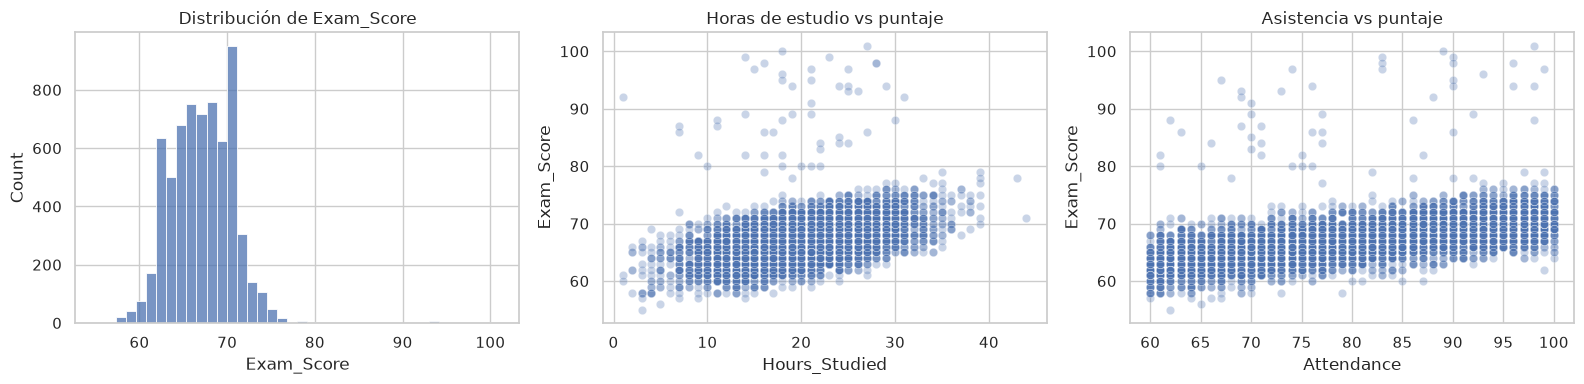

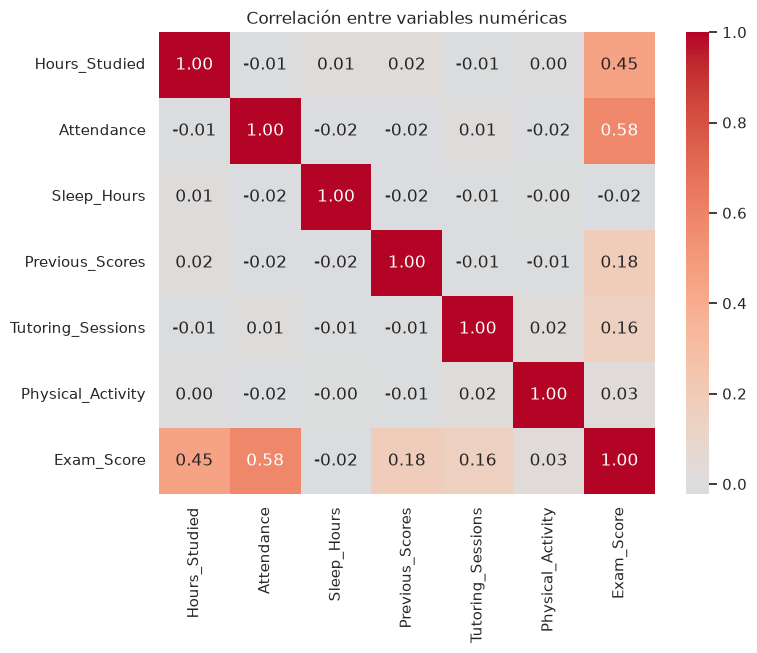

In [7]:
#Visualizamos la variable objetivo y su relación con los dos factores más intuitivos
num_cols_all = df.select_dtypes(include="number").columns
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Exam_Score"], bins=40, ax=axes[0]).set_title("Distribución de Exam_Score")
sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", alpha=.3, ax=axes[1]).set_title("Horas de estudio vs puntaje")
sns.scatterplot(data=df, x="Attendance", y="Exam_Score", alpha=.3, ax=axes[2]).set_title("Asistencia vs puntaje")
plt.tight_layout(); plt.show()

#Matriz de correlación: qué variables numéricas se relacionan linealmente con el puntaje
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols_all].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas"); plt.show()

## 3. Limpieza

- Se eliminan los registros con `Attendance` negativo y con `Exam_Score` fuera de [0, 100].
- Los faltantes (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) se imputan con la **moda** dentro del pipeline, ajustada solo con el conjunto de entrenamiento para evitar fuga de información.

In [8]:
#Eliminamos los registros con valores imposibles (asistencia negativa o puntaje fuera de [0, 100])
n0 = len(df)
df = df[(df["Attendance"] >= 0) & (df["Exam_Score"].between(0, 100))].reset_index(drop=True)
print(f"Registros eliminados: {n0 - len(df)}  ->  quedan {len(df)}")

Registros eliminados: 1  ->  quedan 6606


## 4. Codificación, escalado y partición

Las variables son de tres tipos y cada una se trata distinto:

* **Numéricas** (horas de estudio, asistencia, sueño, etc.): se estandarizan para que todas tengan la misma escala. Esto es importante para Ridge y sobre todo para la red neuronal, que se entrena con descenso de gradiente.
* **Ordinales** (Low/Medium/High, Near/Moderate/Far, etc.): se codifican como enteros respetando su orden.
* **Nominales o binarias** (género, tipo de colegio, acceso a internet, etc.): se codifican con *one-hot*.

Todo se hace dentro de un `Pipeline`, de modo que en la validación cruzada el preprocesamiento se ajusta únicamente con los folds de entrenamiento.

In [9]:
#Separamos las variables de entrada (X) del valor a estimar (y)
TARGET = "Exam_Score"
X = df.drop(columns=TARGET)   #Muestras
y = df[TARGET].values         #Valor a estimar

# Variables categóricas ordinales (tienen un orden natural): se codifican como 0, 1, 2 respetando ese orden
ordinal_map = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
}
ord_cols = list(ordinal_map)
num_cols = X.select_dtypes(include="number").columns.tolist()
nom_cols = [c for c in X.columns if c not in ord_cols + num_cols]   # binarias / nominales
print("Numéricas:", num_cols, "\nOrdinales:", ord_cols, "\nNominales:", nom_cols)

#Preprocesamiento por tipo de variable:
# - numéricas: imputación con la mediana + estandarización
# - ordinales: imputación con la moda + codificación ordinal + estandarización
# - nominales/binarias: imputación con la moda + one-hot (una sola columna si es binaria)
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OrdinalEncoder(categories=[ordinal_map[c] for c in ord_cols])),
                      ("sc", StandardScaler())]), ord_cols),
    ("nom", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), nom_cols),
])

#Seleccionamos 80% de muestras para entrenamiento y 20% para prueba
#El conjunto de prueba no se toca hasta evaluar los modelos finales
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

Numéricas: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity'] 
Ordinales: ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Parental_Education_Level', 'Distance_from_Home'] 
Nominales: ['Extracurricular_Activities', 'Internet_Access', 'School_Type', 'Learning_Disabilities', 'Gender']
Train: (5284, 19)  Test: (1322, 19)


## 5. Línea base (hiperparámetros por defecto)

Entrenamos los tres modelos con los hiperparámetros por defecto de sklearn. Este es el punto de referencia: la optimización de hiperparámetros solo vale la pena si mejora claramente estos resultados.

* **Ridge:** regresión lineal con regularización L2.
* **Random Forest:** ensamble de árboles de decisión.
* **MLP:** perceptrón multicapa (red neuronal).

Usamos el **RMSE** (raíz del error cuadrático medio) como métrica principal porque está en las mismas unidades del puntaje: un RMSE de 2 significa que el modelo se equivoca en unos 2 puntos en promedio.

In [10]:
#Validación cruzada de 5 folds: la usan todos los métodos para que la comparación sea justa
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

#Une el preprocesamiento con el modelo; así la imputación y el escalado se ajustan solo con los folds de entrenamiento
def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

#Evalúa un modelo ya entrenado en el conjunto de prueba y arma una fila de la tabla de resultados
def evaluate(model, name, method, t=np.nan, n_evals=np.nan, cv_rmse=np.nan):
    pred = model.predict(X_test)
    return {"Modelo": name, "Método": method,
            "RMSE_CV": cv_rmse,
            "RMSE_test": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE_test": mean_absolute_error(y_test, pred),
            "R2_test": r2_score(y_test, pred),
            "Tiempo_s": t, "Evaluaciones": n_evals}

#Modelos con los hiperparámetros por defecto de sklearn
base_models = {
    "Ridge": Ridge(),
    "RandomForest": RandomForestRegressor(random_state=SEED),
    "MLP": MLPRegressor(random_state=SEED, max_iter=500),
}
results, best_models = [], {}
for name, m in base_models.items():
    pipe = make_pipe(m)
    t0 = time.time()
    #RMSE promedio de validación cruzada (sklearn lo devuelve negativo porque siempre maximiza)
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    #Entrenamiento con todo el conjunto de entrenamiento y evaluación en prueba
    pipe.fit(X_train, y_train)
    results.append(evaluate(pipe, name, "Por defecto", time.time() - t0, 1, cv_rmse))
    best_models[(name, "Por defecto")] = pipe
pd.DataFrame(results)

,Modelo,Método,RMSE_CV,RMSE_test,MAE_test,R2_test,Tiempo_s,Evaluaciones
0,Ridge,Por defecto,2.081991,1.517830,0.410362,0.825789,1.373627,1
1,RandomForest,Por defecto,2.412316,1.967188,1.053767,0.707368,3.217104,1
2,MLP,Por defecto,2.355861,1.826953,0.933390,0.747603,9.182720,1


## 6. Enfoque A: optimización de hiperparámetros

Se comparan cinco estrategias vistas en clase, todas con **un presupuesto parecido de evaluaciones** (`N_EVALS`) y la misma validación cruzada de 5 folds. La función objetivo es $f(\theta) = \text{RMSE}_{CV}(\theta)$.

| Método | Tipo | Referencia en clase |
|---|---|---|
| Grid Search | Búsqueda exhaustiva en rejilla | Clase 1, notebooks 1, 4 y 5 |
| Random Search | Muestreo aleatorio | Clase 1, notebooks 1, 4 y 5 |
| Bayesiana (`BayesSearchCV`, skopt) | Modelo sustituto (proceso gaussiano) | Clase 1, notebooks 4 y 5 |
| Algoritmo genético (pygad) | Metaheurística evolutiva | Clase 3, notebook 14 |
| PSO (pymetaheuristic) | Metaheurística de enjambre | Clase 3, notebooks 15 y 16 |

Definimos los espacios de búsqueda de cada método. Grid Search necesita una rejilla de valores fijos; Random Search y la búsqueda bayesiana usan distribuciones o rangos continuos. El algoritmo genético y PSO trabajan con vectores de números reales, así que cada hiperparámetro se representa como un **gen** con límites inferior y superior, y la función `decode` convierte ese vector en hiperparámetros válidos (redondeando enteros y usando escala logarítmica para `alpha` y la tasa de aprendizaje).

In [11]:
N_EVALS = 30   # presupuesto aproximado de evaluaciones por método y modelo

class MLPArch(MLPRegressor):
    # MLP cuya arquitectura se pasa como texto ('64-32') para que todos los buscadores la traten como categórica
    # '64-32' significa dos capas ocultas: 64 neuronas y luego 32
    def __init__(self, arch="64", alpha=1e-4, learning_rate_init=1e-3, max_iter=500,
                 early_stopping=True, random_state=None):
        self.arch = arch
        super().__init__(alpha=alpha, learning_rate_init=learning_rate_init, max_iter=max_iter,
                         early_stopping=early_stopping, random_state=random_state)
    def fit(self, X, y):
        #Convertimos el texto en la tupla que espera MLPRegressor, p. ej. '64-32' -> (64, 32)
        self.hidden_layer_sizes = tuple(int(n) for n in self.arch.split("-"))
        return super().fit(X, y)

#Arquitecturas candidatas para la red
ARCHS = ["16", "32", "64", "128", "32-16", "64-32", "128-64"]
#Constructores de cada modelo a partir de un diccionario de hiperparámetros
model_ctor = {"Ridge": lambda **p: Ridge(**p),
              "RandomForest": lambda **p: RandomForestRegressor(random_state=SEED, **p),
              "MLP": lambda **p: MLPArch(random_state=SEED, **p)}

#Espacios de búsqueda. Hiperparámetros optimizados:
# - Ridge: alpha (fuerza de la regularización L2)
# - RandomForest: número de árboles, profundidad máxima, mínimo de muestras por hoja, fracción de variables por división
# - MLP: arquitectura, alpha (regularización L2) y tasa de aprendizaje inicial

# Grid Search: valores fijos en una rejilla (unas 30 combinaciones por modelo)
grids = {
    "Ridge": {"model__alpha": np.logspace(-3, 3, 30)},
    "RandomForest": {"model__n_estimators": [100, 300], "model__max_depth": [5, 10, 20],
                     "model__min_samples_leaf": [1, 2, 4, 8, 16]},
    "MLP": {"model__arch": ["32", "64", "64-32"], "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1],
            "model__learning_rate_init": [1e-3, 1e-2]},
}
# Random Search: distribuciones de las que se muestrean los hiperparámetros
# (loguniform para los que varían en órdenes de magnitud, como alpha y la tasa de aprendizaje)
dists = {
    "Ridge": {"model__alpha": loguniform(1e-3, 1e3)},
    "RandomForest": {"model__n_estimators": randint(50, 401), "model__max_depth": randint(3, 31),
                     "model__min_samples_leaf": randint(1, 21), "model__max_features": uniform(0.2, 0.8)},
    "MLP": {"model__arch": ARCHS, "model__alpha": loguniform(1e-5, 10),
            "model__learning_rate_init": loguniform(1e-4, 1e-1)},
}
# Bayesiana (skopt): mismos rangos que Random Search, expresados como dimensiones de skopt
bayes_spaces = {
    "Ridge": {"model__alpha": Real(1e-3, 1e3, prior="log-uniform")},
    "RandomForest": {"model__n_estimators": Integer(50, 400), "model__max_depth": Integer(3, 30),
                     "model__min_samples_leaf": Integer(1, 20), "model__max_features": Real(0.2, 1.0)},
    "MLP": {"model__arch": Categorical(ARCHS), "model__alpha": Real(1e-5, 10, prior="log-uniform"),
            "model__learning_rate_init": Real(1e-4, 1e-1, prior="log-uniform")},
}
# AG y PSO trabajan con vectores reales: límites de cada gen y cómo se decodifican a hiperparámetros
bounds = {
    "Ridge": [(-3, 3)],                                       # log10(alpha)
    "RandomForest": [(50, 400), (3, 30), (1, 20), (0.2, 1.0)],  # n_estimators, max_depth, min_samples_leaf, max_features
    "MLP": [(0, len(ARCHS) - 1e-6), (-5, 1), (-4, -1)],       # índice de arquitectura, log10(alpha), log10(lr)
}
#Decodificación del cromosoma/partícula: vector real -> diccionario de hiperparámetros válidos
def decode(name, v):
    if name == "Ridge":
        return {"alpha": 10 ** v[0]}
    if name == "RandomForest":
        #Los hiperparámetros enteros se redondean
        return {"n_estimators": int(round(v[0])), "max_depth": int(round(v[1])),
                "min_samples_leaf": int(round(v[2])), "max_features": float(v[3])}
    if name == "MLP":
        #El primer gen se trunca para escoger una arquitectura de la lista
        return {"arch": ARCHS[int(v[0])], "alpha": 10 ** v[1], "learning_rate_init": 10 ** v[2]}

#Función objetivo f(theta): RMSE promedio de validación cruzada para una combinación de hiperparámetros
def cv_rmse(name, params):
    pipe = make_pipe(model_ctor[name](**params))
    return -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()

Ejecutamos las búsquedas. Para cada combinación de hiperparámetros que se evalúa guardamos su RMSE de validación cruzada, así podemos dibujar después las curvas de convergencia. En el AG y en PSO se usa una caché para no volver a evaluar una combinación que ya se había probado. Al terminar cada búsqueda, el mejor modelo se reentrena con todo el conjunto de entrenamiento y se evalúa en prueba.

**Nota:** esta celda es la más costosa del notebook, porque cada evaluación entrena el modelo 5 veces (una por fold).

In [12]:
histories = {}   # RMSE_CV de cada evaluación, en orden, para las curvas de convergencia
best_params = {}

#Guarda los resultados de una búsqueda: historial, mejores hiperparámetros, modelo final y métricas en prueba
def register(name, method, estimator, t, hist, best_cv, params):
    histories[(name, method)] = np.asarray(hist)
    best_params[(name, method)] = params
    best_models[(name, method)] = estimator
    results.append(evaluate(estimator, name, method, t, len(hist), best_cv))
    print(f"{method:10s} RMSE_CV={best_cv:.4f}  evals={len(hist):3d}  ({t:.1f}s)")

#Grid, Random y Bayesiana comparten la interfaz de sklearn (fit, best_estimator_, cv_results_)
def run_sklearn_search(name, method, search):
    t0 = time.time()
    search.fit(X_train, y_train)
    register(name, method, search.best_estimator_, time.time() - t0,
             -search.cv_results_["mean_test_score"], -search.best_score_, search.best_params_)

#AG y PSO: optimizan directamente la función objetivo sobre el vector real de hiperparámetros
def run_metaheuristic(name, method):
    hist, cache = [], {}
    def f(v):                                    # función objetivo a minimizar
        params = decode(name, v)
        key = str(params)
        if key not in cache:                     # no repetir evaluaciones idénticas
            cache[key] = cv_rmse(name, params)
        hist.append(cache[key])
        return cache[key]
    t0 = time.time()
    if method == "AG":
        #Algoritmo genético: 6 individuos x 4 generaciones (+ población inicial) ≈ 30 evaluaciones
        ga = pygad.GA(num_generations=4, sol_per_pop=6, num_parents_mating=3,
                      num_genes=len(bounds[name]),
                      gene_space=[{"low": lo, "high": hi} for lo, hi in bounds[name]],
                      fitness_func=lambda ga, sol, idx: -f(sol),   # pygad maximiza, por eso se usa -RMSE
                      parent_selection_type="tournament", # Selección por torneo para mantener presión selectiva
                      crossover_type="uniform",           # Cruce uniforme: cada hiperparámetro se hereda de uno de los padres
                      mutation_type="random",             # Mutación aleatoria dentro de los rangos definidos
                      keep_parents=1,                     # Elitismo: preserva al mejor padre en la siguiente generación
                      random_seed=SEED)
        ga.run()
        best_v = ga.best_solution()[0]
    else:
        #PSO: 6 partículas x 4 iteraciones (+ enjambre inicial) ≈ 30 evaluaciones
        # w = inercia, c1 = componente cognitiva (mejor posición propia), c2 = componente social (mejor del enjambre)
        res = pymetaheuristic.optimize(algorithm="pso", target_function=f,
                                       min_values=[lo for lo, _ in bounds[name]],
                                       max_values=[hi for _, hi in bounds[name]],
                                       max_steps=4, swarm_size=6, w=0.9, c1=2.0, c2=2.0)
        best_v = res.best_position
    #Con la mejor solución encontrada reentrenamos el modelo con todo el conjunto de entrenamiento
    params = decode(name, best_v)
    est = make_pipe(model_ctor[name](**params)).fit(X_train, y_train)
    register(name, method, est, time.time() - t0, hist, min(hist), params)

#Ejecutamos los cinco métodos de búsqueda para cada uno de los tres modelos
for name in base_models:
    print(f"===== {name} =====")
    run_sklearn_search(name, "Grid", GridSearchCV(make_pipe(model_ctor[name]()), grids[name], cv=cv,
                       scoring="neg_root_mean_squared_error", n_jobs=-1))
    run_sklearn_search(name, "Random", RandomizedSearchCV(make_pipe(model_ctor[name]()), dists[name],
                       n_iter=N_EVALS, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=SEED))
    run_sklearn_search(name, "Bayesiana", BayesSearchCV(make_pipe(model_ctor[name]()), bayes_spaces[name],
                       n_iter=N_EVALS, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=SEED))
    run_metaheuristic(name, "AG")
    run_metaheuristic(name, "PSO")

===== Ridge =====
Grid       RMSE_CV=2.0820  evals= 30  (1.4s)
Random     RMSE_CV=2.0820  evals= 30  (1.0s)
Bayesiana  RMSE_CV=2.0820  evals= 30  (10.9s)
AG         RMSE_CV=2.0820  evals= 29  (1.6s)
PSO        RMSE_CV=2.0820  evals= 30  (1.5s)
===== RandomForest =====
Grid       RMSE_CV=2.3673  evals= 30  (23.5s)
Random     RMSE_CV=2.3290  evals= 30  (16.4s)
Bayesiana  RMSE_CV=2.3311  evals= 30  (59.2s)
AG         RMSE_CV=2.3251  evals= 29  (30.6s)
PSO        RMSE_CV=2.3607  evals= 30  (52.5s)
===== MLP =====
Grid       RMSE_CV=2.1921  evals= 30  (38.1s)
Random     RMSE_CV=2.1137  evals= 30  (76.7s)
Bayesiana  RMSE_CV=2.1002  evals= 30  (63.6s)
AG         RMSE_CV=2.1038  evals= 29  (47.8s)
PSO        RMSE_CV=2.0957  evals= 30  (46.1s)


### 6.1 Resultados

En la tabla, `RMSE_CV` es el mejor valor de la función objetivo que encontró cada método (lo que se optimizó), mientras que `RMSE_test`, `MAE_test` y `R2_test` miden qué tan bien generaliza el modelo final a datos que nunca vio.

In [13]:
#Tabla comparativa: error de validación cruzada, métricas en prueba, tiempo y número de evaluaciones
res = pd.DataFrame(results).round(4)
res

,Modelo,Método,RMSE_CV,RMSE_test,MAE_test,R2_test,Tiempo_s,Evaluaciones
0,Ridge,Por defecto,2.0820,1.5178,0.4104,0.8258,1.3736,1
1,RandomForest,Por defecto,2.4123,1.9672,1.0538,0.7074,3.2171,1
2,MLP,Por defecto,2.3559,1.8270,0.9334,0.7476,9.1827,1
3,Ridge,Grid,2.0820,1.5180,0.4110,0.8258,1.3910,30
4,Ridge,Random,2.0820,1.5179,0.4107,0.8258,0.9508,30
5,Ridge,Bayesiana,2.0820,1.5180,0.4113,0.8257,10.8749,30
6,Ridge,AG,2.0820,1.5180,0.4114,0.8257,1.5531,29
7,Ridge,PSO,2.0820,1.5180,0.4111,0.8258,1.4526,30
8,RandomForest,Grid,2.3673,1.8888,1.0127,0.7302,23.5340,30
9,RandomForest,Random,2.3290,1.8254,0.9502,0.7480,16.4483,30


In [14]:
#Mejores hiperparámetros encontrados por cada método para cada modelo
for k, v in best_params.items():
    print(k, v)

('Ridge', 'Grid') {'model__alpha': np.float64(8.531678524172806)}
('Ridge', 'Random') {'model__alpha': np.float64(4.689400963537685)}
('Ridge', 'Bayesiana') OrderedDict({'model__alpha': 11.083893227166808})
('Ridge', 'AG') {'alpha': np.float64(12.073834860996044)}
('Ridge', 'PSO') {'alpha': 9.09922671024635}
('RandomForest', 'Grid') {'model__max_depth': 20, 'model__min_samples_leaf': 4, 'model__n_estimators': 300}
('RandomForest', 'Random') {'model__max_depth': 28, 'model__max_features': np.float64(0.4436910153386966), 'model__min_samples_leaf': 2, 'model__n_estimators': 389}
('RandomForest', 'Bayesiana') OrderedDict({'model__max_depth': 30, 'model__max_features': 0.4306357698620612, 'model__min_samples_leaf': 2, 'model__n_estimators': 117})
('RandomForest', 'AG') {'n_estimators': 306, 'max_depth': 19, 'min_samples_leaf': 2, 'max_features': 0.40702398528001354}
('RandomForest', 'PSO') {'n_estimators': 148, 'max_depth': 18, 'min_samples_leaf': 4, 'max_features': 0.8417575846032317}
('ML

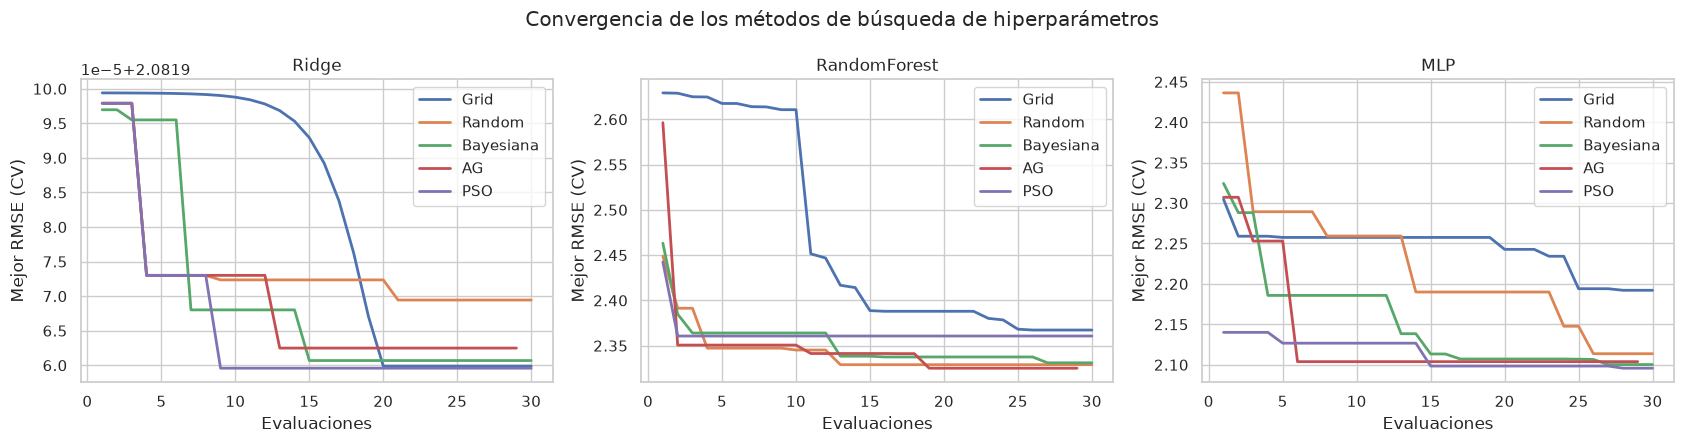

In [15]:
# Curvas de convergencia: mejor RMSE_CV acumulado vs número de evaluaciones
# Una curva que baja rápido indica un método que encuentra buenas soluciones con pocas evaluaciones
METHODS = ["Grid", "Random", "Bayesiana", "AG", "PSO"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, name in zip(axes, base_models):
    for method in METHODS:
        h = histories[(name, method)]
        ax.plot(np.arange(1, len(h) + 1), np.minimum.accumulate(h), label=method, lw=2)
    ax.set_title(name); ax.set_xlabel("Evaluaciones"); ax.set_ylabel("Mejor RMSE (CV)"); ax.legend()
plt.suptitle("Convergencia de los métodos de búsqueda de hiperparámetros"); plt.tight_layout(); plt.show()

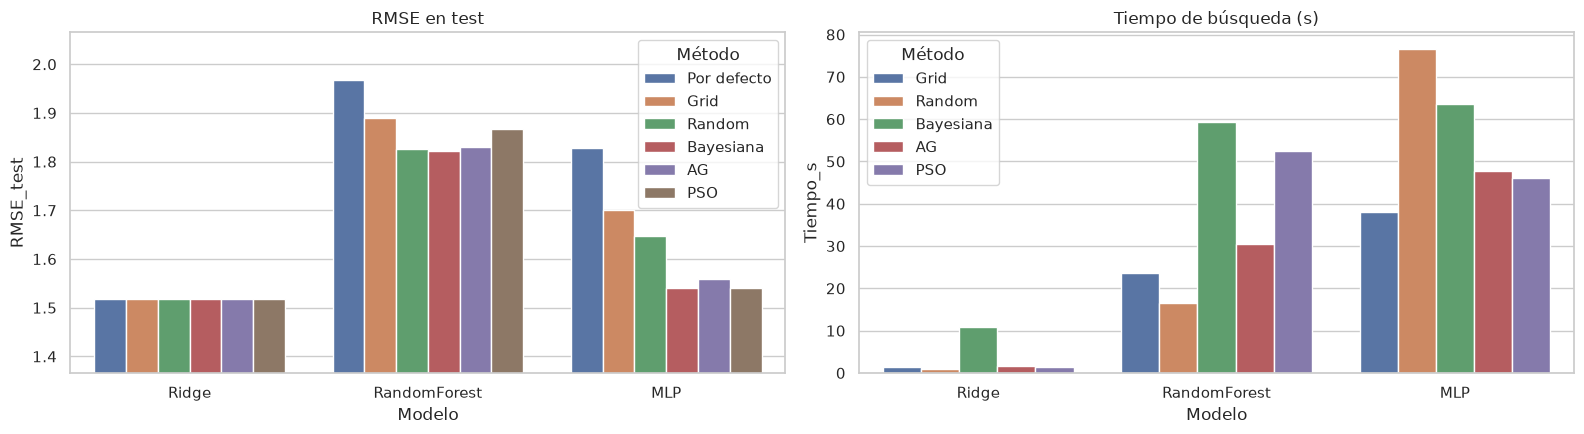

In [16]:
#Comparamos el error en prueba (izquierda) y el costo computacional de cada búsqueda (derecha)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.barplot(data=res, x="Modelo", y="RMSE_test", hue="Método", ax=axes[0]).set_title("RMSE en test")
#Ajustamos el eje y para que se noten las diferencias entre métodos
axes[0].set_ylim(res["RMSE_test"].min() * 0.9, res["RMSE_test"].max() * 1.05)
sns.barplot(data=res[res["Método"] != "Por defecto"], x="Modelo", y="Tiempo_s", hue="Método", ax=axes[1]).set_title("Tiempo de búsqueda (s)")
plt.tight_layout(); plt.show()

## 7. Enfoque B: comparación de optimizadores de entrenamiento

La misma red neuronal (misma arquitectura e inicialización) se entrena con los cuatro optimizadores que se compararon en la Clase 2 (notebook 10): SGD, SGD con momentum, RMSprop y Adam, todos con `lr = 0.001`. Se minimiza el MSE respecto a los pesos. En clase se usó Keras; aquí se usa PyTorch porque TensorFlow todavía no tiene versión para Python 3.14, pero los algoritmos son los mismos.

In [17]:
import torch
import torch.nn as nn
torch.manual_seed(SEED)

#Reutilizamos el mismo preprocesamiento, ajustado solo con el conjunto de entrenamiento
prep_fit = preprocess.fit(X_train)
#Convertimos los datos a tensores de PyTorch
Xtr = torch.tensor(prep_fit.transform(X_train), dtype=torch.float32)
Xte = torch.tensor(prep_fit.transform(X_test), dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
yte = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

#Definición de la red: dos capas ocultas (64 y 32 neuronas, ReLU) y una neurona de salida lineal (regresión)
def make_net():
    torch.manual_seed(SEED)          # misma inicialización para todos
    return nn.Sequential(nn.Linear(Xtr.shape[1], 64), nn.ReLU(),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

#Optimizadores a comparar, todos con la misma tasa de aprendizaje
optimizers = {
    "SGD":          lambda p: torch.optim.SGD(p, lr=1e-3),                 # descenso de gradiente estocástico
    "SGD+Momentum": lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9),   # acumula la dirección de pasos anteriores
    "RMSprop":      lambda p: torch.optim.RMSprop(p, lr=1e-3),             # tasa adaptativa por parámetro
    "Adam":         lambda p: torch.optim.Adam(p, lr=1e-3),                # momentum + tasa adaptativa
}
EPOCHS, BATCH = 100, 64
#Función de pérdida: error cuadrático medio
loss_fn = nn.MSELoss()
curves, opt_results = {}, []

for name, make_opt in optimizers.items():
    #Inicialización
    net = make_net(); opt = make_opt(net.parameters())
    tr_hist, te_hist = [], []
    g = torch.Generator().manual_seed(SEED)   # mismo orden de mini-lotes para todos los optimizadores
    t0 = time.time()
    #Entrenamiento por mini-lotes
    for ep in range(EPOCHS):
        net.train()
        for idx in torch.randperm(len(Xtr), generator=g).split(BATCH):
            opt.zero_grad()                              # reinicia los gradientes
            loss = loss_fn(net(Xtr[idx]), ytr[idx])      # paso hacia adelante y cálculo de la pérdida
            loss.backward(); opt.step()                  # retropropagación y actualización de los pesos
        #Al final de cada época registramos la pérdida en entrenamiento y en prueba
        net.eval()
        with torch.no_grad():
            tr_hist.append(loss_fn(net(Xtr), ytr).item())
            te_hist.append(loss_fn(net(Xte), yte).item())
    curves[name] = (tr_hist, te_hist)
    #Evaluacion final en el conjunto de prueba
    with torch.no_grad():
        pred = net(Xte).numpy().ravel()
    opt_results.append({"Optimizador": name, "RMSE_test": np.sqrt(mean_squared_error(y_test, pred)),
                        "MAE_test": mean_absolute_error(y_test, pred), "R2_test": r2_score(y_test, pred),
                        "Tiempo_s": time.time() - t0})
    print(f"{name:13s} MSE test final = {te_hist[-1]:.3f}")

pd.DataFrame(opt_results).round(4)

SGD           MSE test final = 4.810
SGD+Momentum  MSE test final = 3.531
RMSprop       MSE test final = 2.903
Adam          MSE test final = 3.142


,Optimizador,RMSE_test,MAE_test,R2_test,Tiempo_s
0,SGD,2.1932,1.4832,0.6363,2.6458
1,SGD+Momentum,1.8791,0.9800,0.7330,2.9744
2,RMSprop,1.7037,0.7199,0.7805,3.5675
3,Adam,1.7725,0.8065,0.7624,4.0787


Graficamos la pérdida por época de cada optimizador (escala logarítmica). En este caso el comportamiento no es el esperado a priori: con la misma inicialización, SGD y sobre todo SGD con momentum parten de una pérdida mucho menor en la primera época, mientras que Adam empieza muy alto (MSE ≈ 3000) y desciende de forma suave pero lenta. SGD sin momentum es el más ruidoso, con picos frecuentes durante todo el entrenamiento.

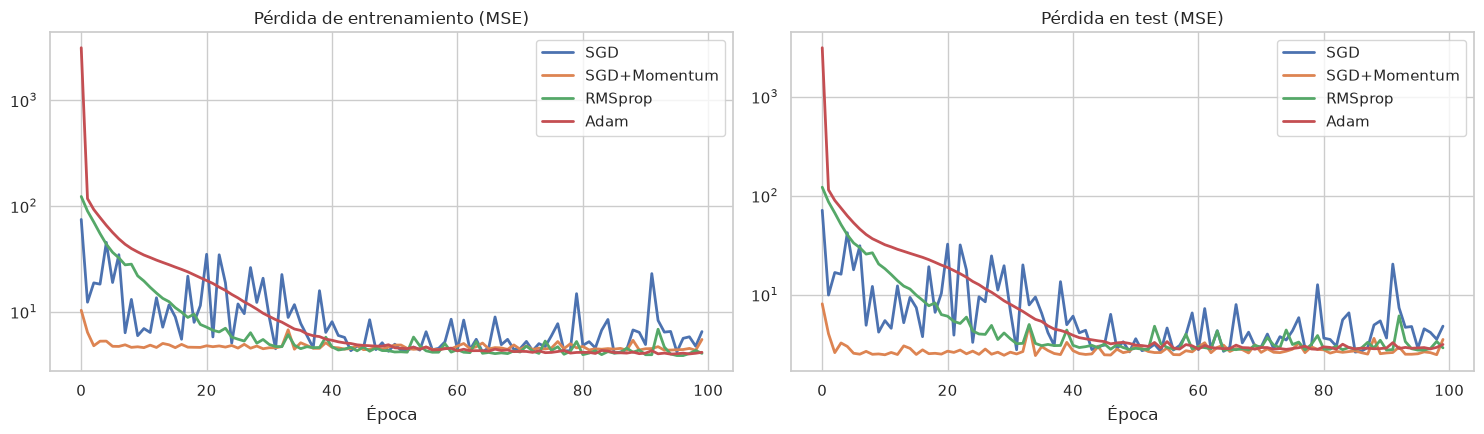

In [18]:
#Curvas de aprendizaje de cada optimizador (escala logarítmica para ver mejor las diferencias)
#Si la pérdida de entrenamiento sigue bajando y la de prueba sube, hay sobreajuste
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, (tr, te) in curves.items():
    axes[0].plot(tr, label=name, lw=2); axes[1].plot(te, label=name, lw=2)
for ax, t in zip(axes, ["Pérdida de entrenamiento (MSE)", "Pérdida en test (MSE)"]):
    ax.set_yscale("log"); ax.set_xlabel("Época"); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.show()

## 8. Análisis de sesgo por grupos

Retomando la sección ética de la primera entrega: ¿el mejor modelo comete errores parecidos en los distintos grupos?

In [19]:
#Escogemos la configuración (modelo + método) con menor RMSE en prueba
best_row = res[res["Método"] != "Por defecto"].sort_values("RMSE_test").iloc[0]
print("Mejor configuración:", best_row["Modelo"], "-", best_row["Método"])
best_model = best_models[(best_row["Modelo"], best_row["Método"])]

#Error absoluto de cada estudiante del conjunto de prueba
err = X_test.copy()
err["abs_err"] = np.abs(y_test - best_model.predict(X_test))
#Error medio y número de estudiantes por grupo de cada variable sensible
for col in ["Family_Income", "Gender", "Learning_Disabilities", "Internet_Access", "School_Type"]:
    print(err.groupby(col)["abs_err"].agg(["mean", "count"]).round(3), "\n")

Mejor configuración: Ridge - Random
                mean  count
Family_Income              
High           0.522    241
Low            0.354    557
Medium         0.419    524 

         mean  count
Gender              
Female  0.443    575
Male    0.386    747 

                        mean  count
Learning_Disabilities              
No                     0.374   1203
Yes                    0.777    119 

                  mean  count
Internet_Access              
No               0.326    103
Yes              0.418   1219 

              mean  count
School_Type              
Private      0.360    424
Public       0.435    898 



## 9. Conclusiones

**Optimización de hiperparámetros (enfoque A)**

- **Ridge:** los cinco métodos llegan al mismo RMSE_CV (2.0820) y prácticamente al mismo RMSE_test (≈1.518) que el modelo por defecto. Las diferencias en la curva de convergencia son del orden de $10^{-5}$, es decir, la función objetivo es casi plana respecto a `alpha` en el rango explorado (los mejores valores van de 4.7 a 12.1). Optimizar Ridge no aporta nada; solo agrega costo (la bayesiana tardó 10.9 s frente a 1.4 s de la línea base).
- **Random Forest:** la optimización sí ayuda: el RMSE_CV baja de 2.412 (por defecto) a 2.325–2.367, y el RMSE_test de 1.967 a ≈1.82–1.89. El mejor RMSE_CV lo obtuvo el **AG (2.3251)**, seguido de cerca por Random (2.3290) y Bayesiana (2.3311). En prueba, Bayesiana (1.8224) y Random (1.8254) quedan ligeramente mejor. Grid Search fue el peor y el más lento en mejorar: su rejilla no incluía `max_features`, que resultó clave (los mejores modelos usan ≈0.41–0.44 de las variables por división). PSO se estancó desde la segunda evaluación en 2.361, señal de convergencia prematura con un enjambre pequeño.
- **MLP:** es donde más se gana: RMSE_CV de 2.356 a 2.096 y RMSE_test de 1.827 a ≈1.54. El mejor RMSE_CV fue el de **PSO (2.0957)**, con Bayesiana (2.1002) y AG (2.1038) muy cerca; en prueba Bayesiana y PSO empatan (≈1.541). Los tres coinciden en una red pequeña (una capa oculta de 32 neuronas) con regularización fuerte (`alpha` entre 6.6 y 10), lo que indica que el problema no necesita una red compleja. Grid (2.1921) y Random (2.1137) quedaron atrás.
- **Velocidad de convergencia:** en las curvas, AG, PSO y la bayesiana alcanzan valores cercanos a su óptimo en las primeras 5–15 evaluaciones, mientras que Grid Search depende del orden de la rejilla y solo mejora cuando llega a la zona buena (en RF hasta la evaluación 10–25). Random Search es competitivo pero irregular. Con presupuestos pequeños como este (30 evaluaciones), los métodos guiados (bayesiana y metaheurísticas) son la mejor opción.
- **Costo:** ningún método domina en tiempo; la bayesiana tiene un sobrecosto fijo por ajustar el proceso gaussiano (se nota en Ridge), y en RF/MLP el tiempo lo dominan los hiperparámetros que se prueban (redes y bosques más grandes tardan más), no el algoritmo de búsqueda. Para RF y MLP el costo (≈20–80 s) se justifica por la mejora; para Ridge no.

**Modelos**

- El modelo que mejor generaliza es **Ridge** (RMSE_test ≈ 1.518, MAE ≈ 0.41, R² ≈ 0.826), incluso con hiperparámetros por defecto. El MLP optimizado se le acerca (1.541, R² ≈ 0.82) y Random Forest queda claramente por debajo (≈1.82, R² ≈ 0.75). Que un modelo lineal gane indica que la relación entre los factores y el `Exam_Score` es **casi lineal y aditiva**; los modelos no lineales solo se acercan cuando se regularizan fuertemente, es decir, cuando se parecen a un modelo lineal.
- El MAE de Ridge (≈0.41) es mucho menor que su RMSE (≈1.52): la mayoría de predicciones son casi exactas y el error se concentra en unos pocos estudiantes con puntajes atípicos (por ejemplo, los muy altos que se ven en el histograma), que el modelo no logra explicar con las variables disponibles.

**Optimizadores de entrenamiento (enfoque B)**

- Con `lr = 0.001` y 100 épocas, el mejor resultado en prueba fue el de **RMSprop** (RMSE 1.704, R² 0.78), seguido de Adam (1.773), SGD+Momentum (1.879) y SGD (2.193). Ninguno alcanzó a Ridge ni al MLP optimizado del enfoque A, que además tenía regularización.
- En velocidad, **SGD+Momentum** fue el más rápido en reducir la pérdida (MSE de prueba ≈ 3 desde las primeras épocas), mientras que Adam partió de una pérdida muy alta y necesitó ≈50 épocas para estabilizarse. Los métodos adaptativos (RMSprop y Adam) tienen curvas más suaves y terminan en una pérdida algo menor. SGD sin momentum es el más inestable, con oscilaciones fuertes hasta el final, lo que explica su peor resultado.
- **Sobreajuste:** no se observa un sobreajuste marcado: las pérdidas de entrenamiento y de prueba se mantienen en el mismo orden (≈3–5) y la de prueba no crece al final. Las diferencias finales entre optimizadores se deben más al ruido de la última época (SGD y SGD+Momentum oscilan) que a sobreajuste; usar *early stopping* o reducir la tasa de aprendizaje al final probablemente los igualaría.

**Sesgo por grupos**

- Con el mejor modelo (Ridge, Random Search) el error absoluto medio es parecido entre géneros (0.44 vs 0.39), tipo de colegio (0.36 vs 0.44), nivel de ingresos (0.35–0.52) y acceso a internet (0.33 vs 0.42); estas diferencias son pequeñas en términos absolutos (menos de 0.2 puntos sobre 100).
- La diferencia relevante está en **`Learning_Disabilities`**: el error para estudiantes con dificultades de aprendizaje (0.78) es el **doble** que para el resto (0.37). Es además un grupo pequeño (119 de 1322 en prueba), por lo que el modelo es menos confiable justamente para la población que más podría necesitar apoyo. Si el modelo se usara para tomar decisiones (por ejemplo, asignar tutorías), habría que validarlo por separado en este grupo, reponderar o recoger más datos antes de usarlo.

## Referencias

- Nguyen, L. *Student Performance Factors*. Kaggle. https://www.kaggle.com/datasets/lainguyn123/student-performance-factors
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13, 281–305.
- Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. *NeurIPS*.
- Gad, A. F. (2023). PyGAD: An intuitive genetic algorithm Python library. *Multimedia Tools and Applications*.
- Kennedy, J., & Eberhart, R. (1995). Particle swarm optimization. *ICNN*.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.